In [6]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)
%pip install scikit-learn

Python version: 3.10.12 (main, Aug 15 2025, 14:32:43) [GCC 11.4.0]
Python executable: /usr/bin/python3
Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 5.0 MB/s  0:00:02a 0:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn]0m 3/4 [scikit-learn]

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans,DBSCAN
from sklearn.mixture import GaussianMixture

from sklearn.metrics import silhouette_score,davies_bouldin_score

print("All required libraries imported successfully")

All required libraries imported successfully


In [12]:
X, y_true = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=1.2,
    random_state=42
)

print("Dataset Shape: ", X.shape)
print("First 5 data points:\n", X[:5])
print("Actual groups: ", np.unique(y_true))

Dataset Shape:  (300, 2)
First 5 data points:
 [[ -9.38956084   6.30370967]
 [ -9.87082379   6.86205626]
 [ -1.52214373   7.54927375]
 [ -7.14084464  -5.56157737]
 [-11.2840772    6.11381934]]
Actual groups:  [0 1 2 3]


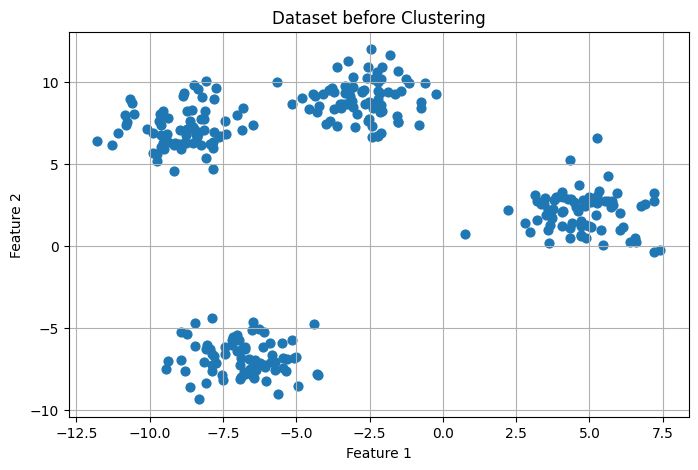

In [14]:
plt.figure(figsize=(8,5))

plt.scatter(X[:, 0], X[:, 1], s=40)

plt.title("Dataset before Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.grid(True)
plt.show()

In [16]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)

kmeans_silhouette = silhouette_score(X, kmeans_labels)

print("Number of clusters : ", len(np.unique(kmeans_labels)))
print("Silhouette score : ", round(kmeans_silhouette,4))

Number of clusters :  4
Silhouette score :  0.7518


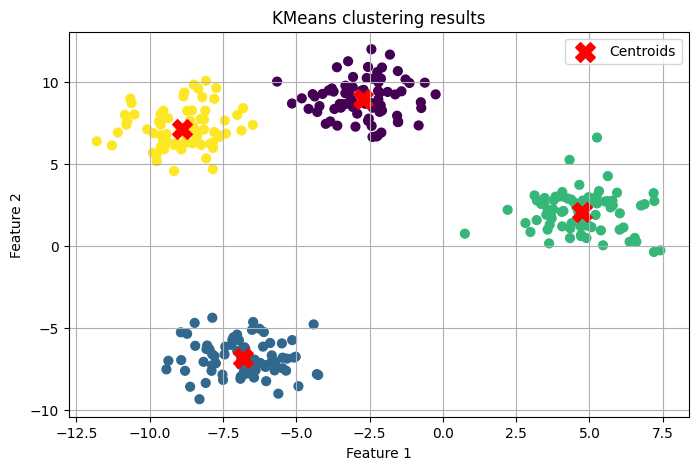

In [21]:
plt.figure(figsize=(8,5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=40
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.title("KMeans clustering results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)

plt.show()

In [25]:
inertias = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)
    inertias.append(model.inertia_)

print("Inertia values: ")
for k, inertia in enumerate(inertias, start=1):
    print(f"K = {k}: {inertia:.2f}")

Inertia values: 
K = 1: 20172.95
K = 2: 9666.83
K = 3: 2346.88
K = 4: 805.48
K = 5: 729.97
K = 6: 656.62
K = 7: 585.09
K = 8: 514.35
K = 9: 461.21
K = 10: 411.74


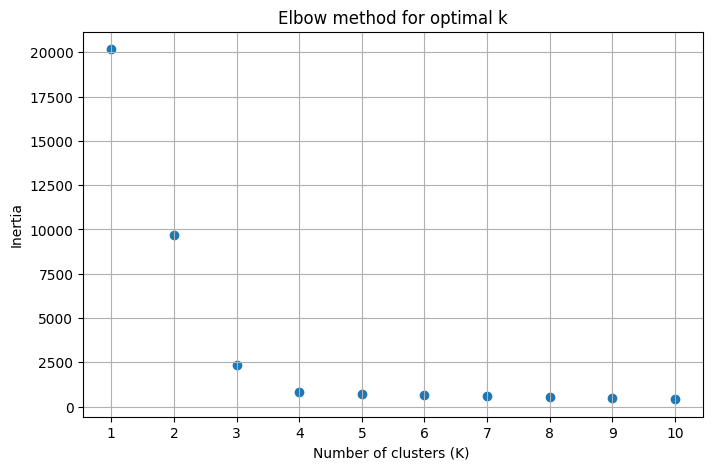

In [29]:
plt.figure(figsize=(8,5))

plt.scatter(
    range(1,11),
    inertias,
    marker='o'
)

plt.title("Elbow method for optimal k")
plt.xlabel("Number of clusters (K) ")
plt.ylabel("Inertia")
plt.xticks(range(1,11))
plt.grid(True)

plt.show()

In [31]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X,labels)
    silhouette_scores.append(score)

    print(f"K = {k} : silhouette score = {score:.4f}")

K = 2 : silhouette score = 0.5772
K = 3 : silhouette score = 0.7352
K = 4 : silhouette score = 0.7518
K = 5 : silhouette score = 0.6327
K = 6 : silhouette score = 0.5080
K = 7 : silhouette score = 0.4122
K = 8 : silhouette score = 0.3406
K = 9 : silhouette score = 0.3460
K = 10 : silhouette score = 0.3649


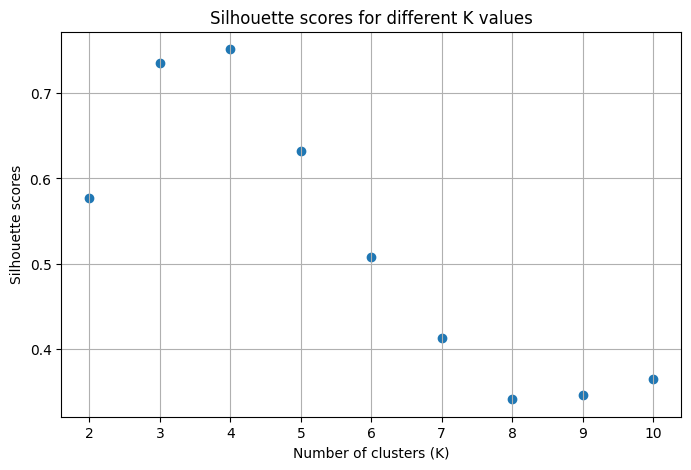

In [33]:
plt.figure(figsize=(8,5))

plt.scatter(
    range(2,11),
    silhouette_scores,
    marker='o'
)

plt.title("Silhouette scores for different K values")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette scores")
plt.xticks(range(2,11))
plt.grid(True)

plt.show()

In [35]:
kmeans_dbi = davies_bouldin_score(X, kmeans_labels)

print("K-Means Silhouette Score:", round(kmeans_silhouette, 4))
print("K-Means Davies-Bouldin Index:", round(kmeans_dbi, 4))

K-Means Silhouette Score: 0.7518
K-Means Davies-Bouldin Index: 0.3472


In [39]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X)

unique_labels = np.unique(dbscan_labels)

n_clusters = len(unique_labels) - (1 if -1 in unique_lables else 0)
n_noise = np.sum(dbscan_labels == -1)

print("Number of clusters : ", n_clusters)
print("Number of noise points : ", n_noise)
print("Unique labels : ", unique_labels)

Number of clusters :  8
Number of noise points :  114
Unique labels :  [-1  0  1  2  3  4  5  6  7]


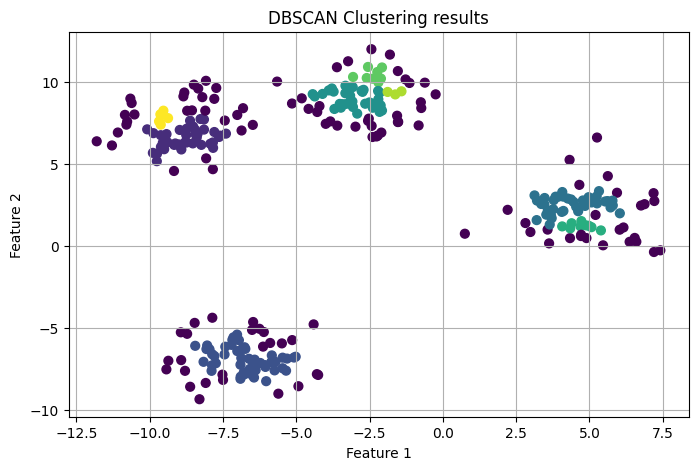

In [41]:
plt.figure(figsize=(8,5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=dbscan_labels,
    cmap='viridis',
    s=40
)

plt.title("DBSCAN Clustering results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)

plt.show()

In [43]:
non_noise_mask = dbscan_labels != -1

X_dbscan = X[non_noise_mask]
labels_dbscan = dbscan_labels[non_noise_mask]

n_dbscan_clusters = len(np.unique(labels_dbscan))

if 2 <= n_dbscan_clusters < len(X_dbscan):
    dbscan_silhouette = silhouette_score(
        X_dbscan,
        labels_dbscan
    )

    dbscan_dbi = davies_bouldin_score(
        X_dbscan,
        labels_dbscan
    )

    print("DBSCAN Silhouette Score:", round(dbscan_silhouette, 4))
    print("DBSCAN Davies-Bouldin Index:", round(dbscan_dbi, 4))
else:
    print("DBSCAN metrics cannot be calculated for this clustering.")

DBSCAN Silhouette Score: 0.4655
DBSCAN Davies-Bouldin Index: 0.7039


In [45]:
eps_values = [0.5, 0.8, 1.0, 1.2, 1.5, 2.0]

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)

    print(
        f"eps = {eps}: "
        f"Clusters = {n_clusters}, "
        f"Noise points = {n_noise}"
    )

eps = 0.5: Clusters = 8, Noise points = 114
eps = 0.8: Clusters = 6, Noise points = 35
eps = 1.0: Clusters = 4, Noise points = 12
eps = 1.2: Clusters = 4, Noise points = 6
eps = 1.5: Clusters = 4, Noise points = 3
eps = 2.0: Clusters = 3, Noise points = 1


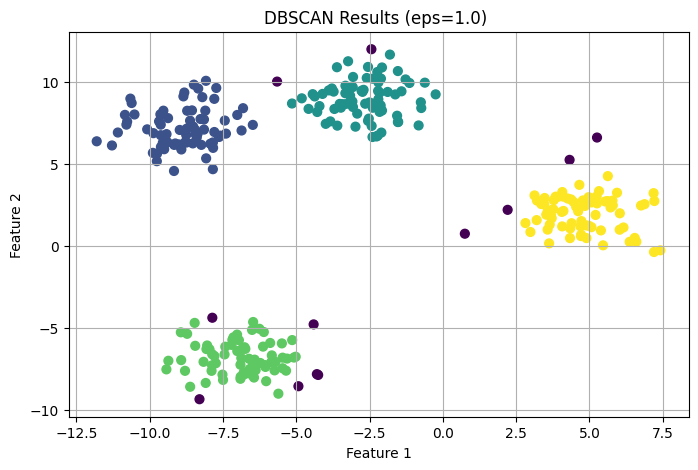

In [47]:
dbscan_tuned = DBSCAN(
    eps=1.0,
    min_samples=5
)

tuned_labels = dbscan_tuned.fit_predict(X)

plt.figure(figsize=(8,5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=tuned_labels,
    cmap='viridis',
    s=40
)

plt.title("DBSCAN Results (eps=1.0) ")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)

plt.show()

In [49]:
tuned_mask = tuned_labels != -1

X_tuned = X[tuned_mask]
labels_tuned = tuned_labels[tuned_mask]

n_clusters_tuned = len(np.unique(labels_tuned))
n_noise_tuned = np.sum(~tuned_mask)

if 2 <= n_clusters_tuned < len(X_tuned):
    tuned_silhouette = silhouette_score(X_tuned, labels_tuned)
    tuned_dbi = davies_bouldin_score(X_tuned, labels_tuned)

    print("Clusters:", n_clusters_tuned)
    print("Noise points:", n_noise_tuned)
    print("Silhouette Score:", round(tuned_silhouette, 4))
    print("Davies-Bouldin Index:", round(tuned_dbi, 4))
else:
    print("Not enough clusters to calculate these metrics.")

Clusters: 4
Noise points: 12
Silhouette Score: 0.762
Davies-Bouldin Index: 0.337


In [51]:
gmm = GaussianMixture(
    n_components=4,
    random_state=42
)

gmm_labels = gmm.fit_predict(X)

gmm_silhouette = silhouette_score(X, gmm_labels)
gmm_dbi = davies_bouldin_score(X, gmm_labels)

print("Number of clusters:", len(np.unique(gmm_labels)))
print("GMM Silhouette Score:", round(gmm_silhouette, 4))
print("GMM Davies-Bouldin Index:", round(gmm_dbi, 4))
print("GMM Converged:", gmm.converged_)

Number of clusters: 4
GMM Silhouette Score: 0.7518
GMM Davies-Bouldin Index: 0.3472
GMM Converged: True


In [53]:
gmm_probabilities = gmm.predict_proba(X)

print("Probability matrix shape:", gmm_probabilities.shape)

print("\nProbabilities for first 5 data points:")
print(np.round(gmm_probabilities[:5], 4))

print("\nProbability sum for first data point:")
print(round(np.sum(gmm_probabilities[0]), 4))

Probability matrix shape: (300, 4)

Probabilities for first 5 data points:
[[0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]]

Probability sum for first data point:
1.0


In [55]:
import pandas as pd

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN (eps=1.0)", "GMM"],
    "Clusters": [4, 4, 4],
    "Noise Points": [0, 12, 0],
    "Silhouette Score": [
        kmeans_silhouette,
        tuned_silhouette,
        gmm_silhouette
    ],
    "Davies-Bouldin Index": [
        kmeans_dbi,
        tuned_dbi,
        gmm_dbi
    ]
})

comparison.round(4)

,Algorithm,Clusters,Noise Points,Silhouette Score,Davies-Bouldin Index
0,K-Means,4,0,0.7518,0.3472
1,DBSCAN (eps=1.0),4,12,0.7620,0.3370
2,GMM,4,0,0.7518,0.3472
